# Exploratory Data Analysis (EDA) terhadap Ulasan Pemain CS:GO di Steam

#


### 1. Import Library dan Membaca Dataset

Pada tahap pertama ini, saya menyiapkan beberapa library Python yang akan digunakan untuk mengolah dan menganalisis data. Selanjutnya, saya membaca file CSV yang berisi ulasan pemain CS:GO dari Steam. Setelah data berhasil dibaca, saya menampilkan jumlah baris, jumlah kolom, dan lima data pertama untuk melihat gambaran awal dari dataset yang digunakan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("csgo_steam_reviews.csv")

print("Jumlah baris data:", df.shape[0])
print("Jumlah kolom data:", df.shape[1])

display(df.head())

Jumlah baris data: 15640
Jumlah kolom data: 16


,id,language,review,created,voted_up,votes_up,comment_count,steam_purchase,recieved_for_free,written_during_early_access,author.num_games_owned,author_num_reviews,author_playtime_forever,author_playtime_last_two_weeks,author_playtime_at_review,author_last_played
0,133848242,english,Pretty good game all around.\nGreat game! I wo...,2023-03-01 09:17:12,True,0,0,True,True,False,8,1,44277,1075,44277,2023-03-01 09:04:32
1,133848123,english,haha smiriva me\n,2023-03-01 09:13:21,True,0,0,False,False,False,1,1,2169,2169,2169,2023-03-01 09:16:29
2,133848052,english,full of cheaterts roblox has better anti cheat,2023-03-01 09:11:10,False,0,0,True,False,False,18,3,15619,1976,15603,2023-03-01 09:15:00
3,133847297,english,"Good game, kinda racist but good.",2023-03-01 08:45:24,True,0,0,True,False,False,10,1,14826,2452,14826,2023-02-27 21:09:37
4,133847187,english,mrazq rusnacite ama ovr stava,2023-03-01 08:41:36,True,0,0,True,False,False,10,1,5045,400,4984,2023-03-01 09:30:07


Jadi, disini terlihat ada Jumlah Baris Data sekitar 15.640 dan Jumlah Kolom Data sekitar 16.

#

### 2. Memahami Struktur Dataset

Setelah dataset berhasil dibaca, saya ingin melihat isi dan struktur datanya lebih jelas. Pada tahap ini, saya memeriksa informasi setiap kolom, tipe data yang digunakan, serta ringkasan statistik yang tersedia. Dengan begitu, saya bisa mengetahui gambaran awal dataset sebelum melanjutkan ke tahap berikutnya.

In [2]:
df.info()

display(df.describe())

print("Tipe data setiap kolom:")
display(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 15640 entries, 0 to 15639
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   id                              15640 non-null  int64
 1   language                        15640 non-null  str  
 2   review                          15586 non-null  str  
 3   created                         15640 non-null  str  
 4   voted_up                        15640 non-null  bool 
 5   votes_up                        15640 non-null  int64
 6   comment_count                   15640 non-null  int64
 7   steam_purchase                  15640 non-null  bool 
 8   recieved_for_free               15640 non-null  bool 
 9   written_during_early_access     15640 non-null  bool 
 10  author.num_games_owned          15640 non-null  int64
 11  author_num_reviews              15640 non-null  int64
 12  author_playtime_forever         15640 non-null  int64
 13  author_playt

,id,votes_up,comment_count,author.num_games_owned,author_num_reviews,author_playtime_forever,author_playtime_last_two_weeks,author_playtime_at_review
count,1.564000e+04,15640.000000,15640.000000,15640.000000,15640.000000,1.564000e+04,15640.000000,1.564000e+04
mean,1.328505e+08,0.297123,0.029284,23.599361,3.096931,2.689457e+04,1266.262916,2.553827e+04
std,5.696002e+05,10.447033,0.971049,66.440527,5.775679,5.708865e+04,1841.675192,5.680198e+04
min,1.318581e+08,0.000000,0.000000,0.000000,1.000000,1.000000e+01,0.000000,5.000000e+00
25%,1.323536e+08,0.000000,0.000000,2.000000,1.000000,2.346000e+03,101.000000,1.426000e+03
50%,1.328441e+08,0.000000,0.000000,6.000000,1.000000,7.857000e+03,674.000000,6.241000e+03
75%,1.333328e+08,0.000000,0.000000,21.000000,3.000000,2.887025e+04,1741.250000,2.676925e+04
max,1.338482e+08,1242.000000,118.000000,2062.000000,156.000000,2.788226e+06,20130.000000,2.785245e+06


Tipe data setiap kolom:


id                                int64
language                            str
review                              str
created                             str
voted_up                           bool
votes_up                          int64
comment_count                     int64
steam_purchase                     bool
recieved_for_free                  bool
written_during_early_access        bool
author.num_games_owned            int64
author_num_reviews                int64
author_playtime_forever           int64
author_playtime_last_two_weeks    int64
author_playtime_at_review         int64
author_last_played                  str
dtype: object

Setelah dataset berhasil dibaca, disini terlihat kolom "review" memiliki 15.586 data terisi, berarti ada 54 ulasan yang kosong. Kolom lainnya memiliki 15.640 data terisi, pada df.describe(), kolom votes_up memiliki rata-rata sekitar 0,29, sedangkan nilai maksimumnya mencapai 1.242.

Artinya, sebagian besar ulasan kemungkinan memiliki sedikit atau tidak memiliki suara positif, tetapi ada ulasan yang mendapat banyak suara.

#


### 3. Pemeriksaan Data Kosong dan Duplikat

Pada tahap ini, saya memeriksa apakah ada data yang kosong atau baris yang tercatat lebih dari satu kali. Pemeriksaan ini dilakukan supaya saya bisa mengetahui kondisi dataset sebelum melanjutkan ke proses analisis. Jika ditemukan masalah, saya akan melihatnya terlebih dahulu sebelum menentukan apakah data perlu diperbaiki atau dihapus.

#### Hasil Pemeriksaan Data

In [3]:
print("Jumlah data kosong:")
display(df.isnull().sum())

print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah data kosong:


id                                 0
language                           0
review                            54
created                            0
voted_up                           0
votes_up                           0
comment_count                      0
steam_purchase                     0
recieved_for_free                  0
written_during_early_access        0
author.num_games_owned             0
author_num_reviews                 0
author_playtime_forever            0
author_playtime_last_two_weeks     0
author_playtime_at_review          0
author_last_played                 0
dtype: int64

Jumlah baris duplikat: 0


Dari hasil pemeriksaan, terdapat 54 data kosong pada kolom "review", sedangkan kolom lainnya tidak memiliki data kosong. Selain itu, tidak ditemukan baris yang duplikat pada dataset ini. Data kosong tersebut akan diperiksa lebih lanjut sebelum menentukan langkah penanganan yang sesuai.

#### Hasil Pemeriksaan Ulasan Kosong

In [4]:
data_kosong = df[df["review"].isnull()]

print("Jumlah data kosong berdasarkan voted_up:")
display(data_kosong["voted_up"].value_counts())

display(data_kosong.head())

Jumlah data kosong berdasarkan voted_up:


voted_up
True     44
False    10
Name: count, dtype: int64

,id,language,review,created,voted_up,votes_up,comment_count,steam_purchase,recieved_for_free,written_during_early_access,author.num_games_owned,author_num_reviews,author_playtime_forever,author_playtime_last_two_weeks,author_playtime_at_review,author_last_played
101,133833608,english,NaN,2023-03-01 01:49:48,True,0,0,False,False,False,8,1,2749,144,2749,2023-03-01 01:44:17
210,133822174,english,NaN,2023-02-28 21:33:56,True,0,0,True,False,False,62,6,6091,1305,6091,2023-02-28 21:31:31
240,133819944,english,NaN,2023-02-28 20:53:01,False,0,0,True,False,False,1,1,746,746,688,2023-02-28 21:32:38
582,133783304,english,NaN,2023-02-28 06:23:23,False,0,0,False,False,False,62,4,22087,976,21990,2023-03-01 05:23:29
1633,133650220,english,NaN,2023-02-26 10:06:43,True,0,0,False,True,False,1,1,5566,1586,5160,2023-02-28 19:54:31


Dari hasil pemeriksaan, ditemukan 54 data yang tidak memiliki isi ulasan. Dari jumlah tersebut, 44 data memiliki label positif dan 10 data memiliki label negatif. Meskipun teks ulasannya kosong, data tersebut masih memiliki informasi lain yang bisa digunakan. Oleh karena itu, data akan tetap dipertahankan pada dataset utama, sedangkan untuk analisis isi ulasan saya akan menggunakan data yang memiliki teks ulasan.

In [5]:
df_review = df.dropna(subset=["review"]).copy()

print("Jumlah data awal:", len(df))
print("Jumlah ulasan yang terisi:", len(df_review))
print("Jumlah ulasan kosong:", df["review"].isnull().sum())

Jumlah data awal: 15640
Jumlah ulasan yang terisi: 15586
Jumlah ulasan kosong: 54


#


### 4. Exploratory Data Analysis (EDA)

Pada bagian ini, saya mulai mengeksplorasi data ulasan pemain CS:GO di Steam untuk melihat pola yang ada di dalam dataset. Analisis dilakukan menggunakan tabel, statistik, dan grafik agar informasi yang terdapat pada data lebih mudah dipahami.


#### 4.1 Distribusi Ulasan Positif dan Negatif

Pada tahap ini, saya mulai melihat pola yang ada pada data ulasan pemain CS:GO di Steam. Analisis pertama dilakukan dengan membandingkan jumlah ulasan yang memberikan rekomendasi positif dan negatif. Hasilnya akan ditampilkan dalam bentuk grafik batang agar perbedaan jumlah keduanya lebih mudah dilihat.

In [6]:
jumlah_ulasan = df["voted_up"].map({
    True: "Positif",
    False: "Negatif"
}).value_counts().reindex(["Positif", "Negatif"], fill_value=0)

print("Jumlah ulasan berdasarkan rekomendasi:")
display(jumlah_ulasan.rename_axis("Kategori").reset_index(name="Jumlah"))

Jumlah ulasan berdasarkan rekomendasi:


,Kategori,Jumlah
0,Positif,13979
1,Negatif,1661


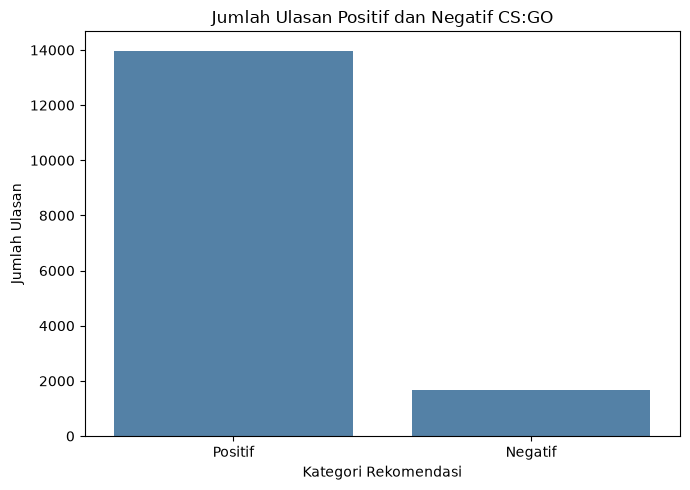

In [7]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=jumlah_ulasan.index,
    y=jumlah_ulasan.values,
    color="steelblue"
)

plt.title("Jumlah Ulasan Positif dan Negatif CS:GO")
plt.xlabel("Kategori Rekomendasi")
plt.ylabel("Jumlah Ulasan")

plt.tight_layout()
plt.show()

Dari Grafik di atas ini menampilkan dua batang Positif dan Negatif. Tinggi batang menunjukkan jumlah ulasan terhadap game CS:GO di Steam untuk setiap kategori. Pada kategori Positif jumlah ulasan sekitar 13.979 dan pada kategori Negatif jumlah ulasan sekitar 1.661.


#### 4.2 Analisis Waktu Bermain Pemain

Pada bagian ini, saya ingin melihat perbedaan waktu bermain antara pemain yang memberikan ulasan positif dan negatif. Untuk mengetahuinya, saya menggunakan nilai median dari total waktu bermain pemain. Hasilnya kemudian ditampilkan dalam bentuk grafik batang agar lebih mudah dibandingkan.

In [8]:
waktu_bermain = df.groupby("voted_up")[
    "author_playtime_forever"
].median() / 60

waktu_bermain.index = waktu_bermain.index.map({
    True: "Positif",
    False: "Negatif"
})

waktu_bermain = waktu_bermain.reindex(["Positif", "Negatif"])

print("Median waktu bermain berdasarkan ulasan (jam):")
display(waktu_bermain.round(2))

Median waktu bermain berdasarkan ulasan (jam):


voted_up
Positif    122.40
Negatif    242.13
Name: author_playtime_forever, dtype: float64

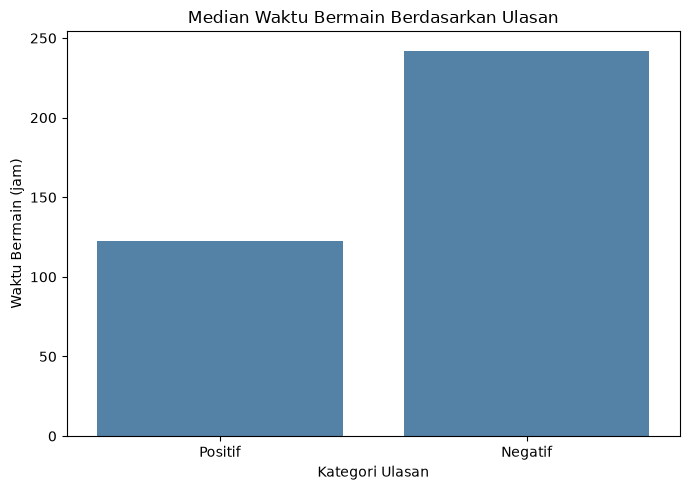

In [9]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=waktu_bermain.index,
    y=waktu_bermain.values,
    color="steelblue"
)

plt.title("Median Waktu Bermain Berdasarkan Ulasan")
plt.xlabel("Kategori Ulasan")
plt.ylabel("Waktu Bermain (jam)")

plt.tight_layout()
plt.show()

Dari grafik di atas, terlihat bahwa pemain yang memberikan ulasan negatif memiliki median waktu bermain yang lebih tinggi dibandingkan pemain yang memberikan ulasan positif. Median waktu bermain untuk ulasan positif sebesar 122,40 jam, sedangkan ulasan negatif sebesar 242,13 jam.

Dari hasil tersebut, saya melihat bahwa pemain yang memberikan ulasan negatif dalam dataset ini ternyata memiliki waktu bermain yang lebih lama. Namun, hasil ini belum tentu berarti semakin lama bermain, pemain akan semakin tidak menyukai game tersebut. Masih ada faktor lain yang mungkin memengaruhi ulasan pemain.


#### 4.3 Persentase Ulasan Positif dan Negatif

Pada bagian ini, saya ingin melihat perbandingan persentase ulasan positif dan negatif yang diberikan oleh pemain CS:GO di Steam. Sebelumnya, saya sudah melihat jumlah ulasan dari kedua kategori tersebut. Kali ini, hasilnya dihitung dalam bentuk persentase agar perbandingannya lebih mudah dipahami.


In [10]:
kategori = df["voted_up"].map({
    True: "Positif",
    False: "Negatif"
})

jumlah = kategori.value_counts().reindex(["Positif", "Negatif"])

persentase = jumlah / len(df) * 100

hasil_ulasan = pd.DataFrame({
    "Jumlah Ulasan": jumlah,
    "Persentase (%)": persentase.round(2)
})

display(hasil_ulasan)

,Jumlah Ulasan,Persentase (%)
voted_up,,
Positif,13979,89.38
Negatif,1661,10.62


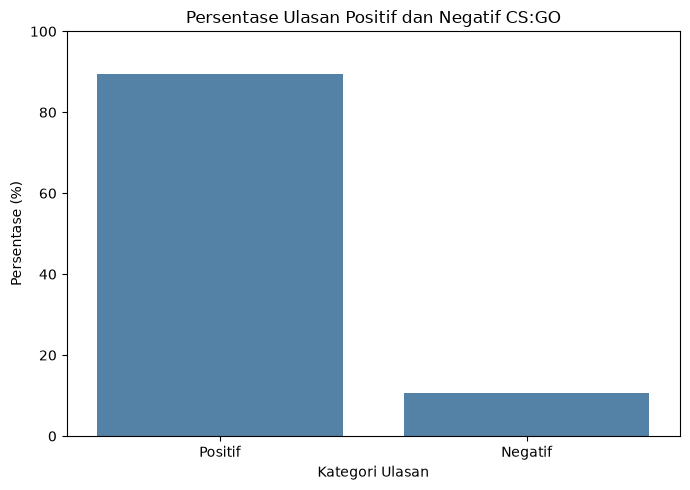

In [11]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=hasil_ulasan.index,
    y=hasil_ulasan["Persentase (%)"],
    color="steelblue"
)

plt.title("Persentase Ulasan Positif dan Negatif CS:GO")
plt.xlabel("Kategori Ulasan")
plt.ylabel("Persentase (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

Berdasarkan hasil perhitungan, sebanyak 89,38% ulasan termasuk dalam kategori positif, sedangkan 10,62% lainnya termasuk kategori negatif. Hasil ini menunjukkan bahwa ulasan dalam dataset yang digunakan lebih banyak memberikan rekomendasi positif terhadap CS:GO.

Meskipun begitu, hasil ini hanya menggambarkan data ulasan yang tersedia dan belum tentu mewakili seluruh pendapat pemain CS:GO.

#### 4.4 Analisis Jumlah Upvote pada Ulasan

Pada bagian ini, saya ingin melihat berapa banyak ulasan yang mendapat upvote dari pengguna lain. Saya membagi ulasan menjadi dua kelompok, yaitu ulasan yang belum mendapat upvote dan ulasan yang sudah mendapat upvote. Dengan cara ini, saya bisa mengetahui seberapa banyak ulasan yang mendapat tanggapan dari pengguna lain.

In [12]:
jumlah_upvote = pd.Series({
    "Belum mendapat upvote": (df["votes_up"] == 0).sum(),
    "Sudah mendapat upvote": (df["votes_up"] > 0).sum()
})

persentase_upvote = jumlah_upvote / len(df) * 100

hasil_upvote = pd.DataFrame({
    "Jumlah Ulasan": jumlah_upvote,
    "Persentase (%)": persentase_upvote.round(2)
})

display(hasil_upvote)


,Jumlah Ulasan,Persentase (%)
Belum mendapat upvote,13448,85.98
Sudah mendapat upvote,2192,14.02


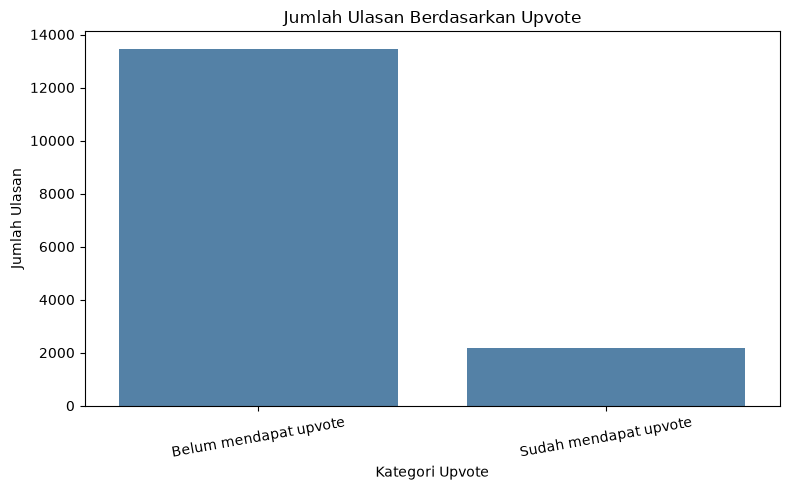

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=hasil_upvote.index,
    y=hasil_upvote["Jumlah Ulasan"],
    color="steelblue"
)

plt.title("Jumlah Ulasan Berdasarkan Upvote")
plt.xlabel("Kategori Upvote")
plt.ylabel("Jumlah Ulasan")
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()

Dari hasil perhitungan, sebagian besar ulasan dalam dataset belum mendapat upvote dari pengguna lain. Terdapat 13.448 ulasan atau sekitar 85,98% yang belum mendapat upvote, sedangkan 2.192 ulasan atau sekitar 14,02% sudah mendapat upvote.

Dari hasil tersebut, terlihat bahwa hanya sebagian kecil ulasan yang mendapat upvote. Namun, hal ini tidak berarti ulasan tersebut buruk atau tidak bermanfaat, karena jumlah upvote juga bisa dipengaruhi oleh berbagai faktor.

#### 4.5 Analisis Bahasa Ulasan

Pada bagian ini, saya ingin melihat bahasa yang digunakan dalam ulasan pemain CS:GO di Steam. Pemeriksaan ini dilakukan untuk mengetahui apakah ulasan dalam dataset menggunakan bahasa yang beragam atau hanya satu bahasa saja.

In [14]:
jumlah_bahasa = df["language"].value_counts()

persentase_bahasa = df["language"].value_counts(normalize=True) * 100

hasil_bahasa = pd.DataFrame({
    "Jumlah Ulasan": jumlah_bahasa,
    "Persentase (%)": persentase_bahasa.round(2)
})

display(hasil_bahasa)


,Jumlah Ulasan,Persentase (%)
language,,
english,15640,100.0


Dari hasil pemeriksaan yang saya lakukan, seluruh 15.640 baris data memiliki nilai `language` berupa `english`. Artinya, dataset yang digunakan hanya memiliki satu kategori bahasa, sehingga belum bisa digunakan untuk membandingkan ulasan berdasarkan bahasa yang berbeda. Oleh karena itu, analisis bahasa cukup ditampilkan dalam bentuk tabel tanpa perlu membuat grafik.

#### 4.6 Analisis Status Pembelian dan Ulasan Pemain

Pada bagian ini, saya ingin melihat perbandingan ulasan positif dan negatif berdasarkan status pembelian game melalui Steam. Data akan dikelompokkan berdasarkan status pembelian, kemudian dihitung jumlah dan persentase ulasannya. Dengan cara ini, saya bisa melihat apakah terdapat perbedaan pola ulasan antara kedua kelompok tersebut.

In [15]:
status_pembelian = df["steam_purchase"].map({
    True: "Dibeli melalui Steam",
    False: "Tidak melalui Steam"
})

kategori_ulasan = df["voted_up"].map({
    True: "Positif",
    False: "Negatif"
})

jumlah_pembelian = pd.crosstab(
    status_pembelian, kategori_ulasan
)

jumlah_pembelian = jumlah_pembelian.reindex(
    index=["Dibeli melalui Steam", "Tidak melalui Steam"],
    columns=["Positif", "Negatif"]
)

print("Jumlah ulasan berdasarkan status pembelian:")
display(jumlah_pembelian)

persentase_pembelian = pd.crosstab(
    status_pembelian, kategori_ulasan, normalize="index"
) * 100

persentase_pembelian = persentase_pembelian.reindex(
    index=["Dibeli melalui Steam", "Tidak melalui Steam"],
    columns=["Positif", "Negatif"]
)

print("Persentase ulasan berdasarkan status pembelian:")
display(persentase_pembelian.round(2))

Jumlah ulasan berdasarkan status pembelian:


voted_up,Positif,Negatif
steam_purchase,,
Dibeli melalui Steam,7552,948
Tidak melalui Steam,6427,713


Persentase ulasan berdasarkan status pembelian:


voted_up,Positif,Negatif
steam_purchase,,
Dibeli melalui Steam,88.85,11.15
Tidak melalui Steam,90.01,9.99


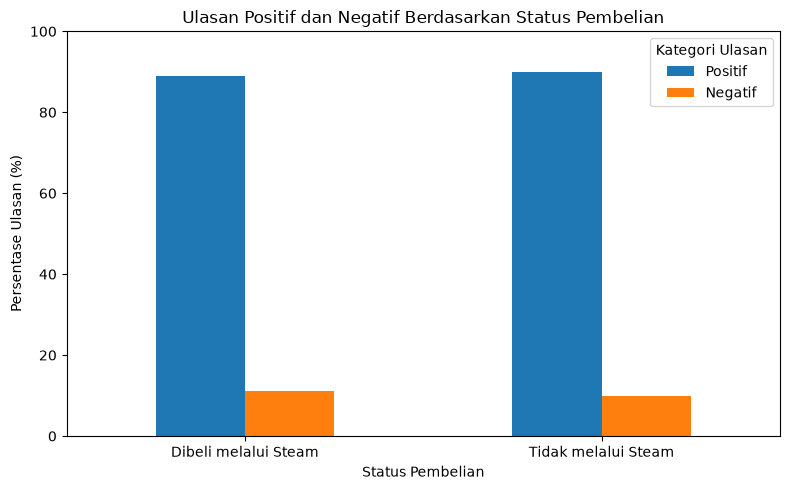

In [16]:
persentase_pembelian.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Ulasan Positif dan Negatif Berdasarkan Status Pembelian")
plt.xlabel("Status Pembelian")
plt.ylabel("Persentase Ulasan (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Kategori Ulasan")

plt.tight_layout()
plt.show()

Dari hasil perhitungan, kedua kelompok memiliki persentase ulasan positif yang cukup tinggi. Pada kelompok yang membeli game melalui Steam, sebanyak 88,85% ulasan bersifat positif. Sementara itu, pada kelompok yang tidak tercatat membeli melalui Steam, persentase ulasan positif mencapai 90,01%.

Perbedaannya tidak terlalu besar. Dari hasil ini, saya melihat bahwa kedua kelompok sama-sama lebih banyak memberikan ulasan positif. Namun, hasil tersebut hanya menunjukkan pola dalam dataset dan belum membuktikan bahwa status pembelian memengaruhi penilaian pemain terhadap game.


#### 4.7 Distribusi Data Numerik

Pada bagian ini, saya ingin melihat beberapa data numerik yang terdapat dalam dataset. Histogram digunakan untuk mengetahui bagaimana data tersebar dan melihat apakah ada nilai yang jauh berbeda dibandingkan sebagian besar data lainnya.

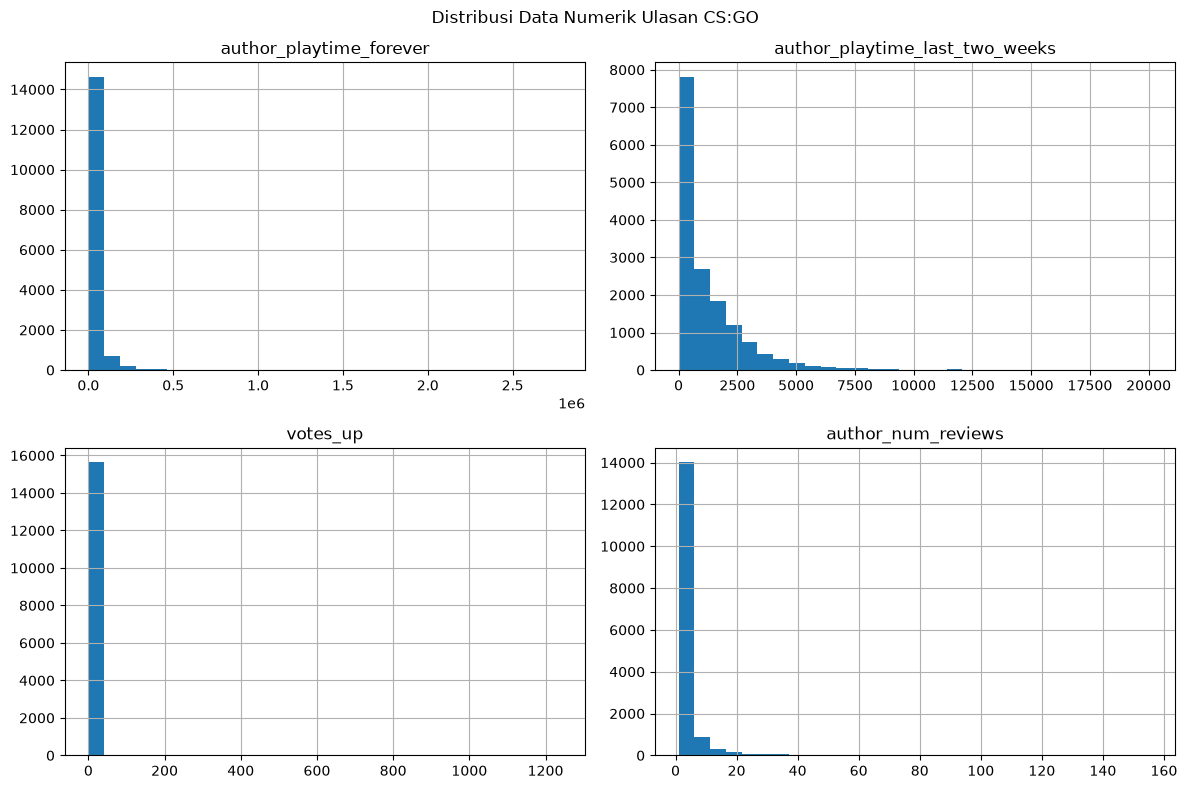

In [17]:
kolom_histogram = [
    "author_playtime_forever",
    "author_playtime_last_two_weeks",
    "votes_up",
    "author_num_reviews"
]

df[kolom_histogram].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle("Distribusi Data Numerik Ulasan CS:GO")
plt.tight_layout()
plt.show()

Hasil histogram menunjukkan bahwa beberapa variabel numerik memiliki distribusi yang cenderung condong ke kanan. Sebagian besar data berada pada rentang nilai yang relatif rendah, sedangkan sebagian kecil memiliki nilai yang jauh lebih tinggi dibandingkan data lainnya. Pola ini terlihat pada variabel waktu bermain, jumlah upvote, dan jumlah ulasan yang ditulis. Khusus pada variabel `votes_up`, sekitar 85,98% ulasan tidak mendapatkan upvote. Nilai yang tinggi tersebut belum tentu merupakan kesalahan data, tetapi menunjukkan adanya perbedaan nilai yang cukup besar antarobservasi dalam dataset.

#### 4.8 Korelasi Antarvariabel Numerik

Pada tahap ini, saya ingin melihat hubungan antara beberapa variabel numerik dalam dataset. Heatmap korelasi digunakan untuk membantu mengetahui variabel mana yang memiliki hubungan lebih kuat atau lebih lemah. Hasilnya akan menjadi gambaran awal mengenai hubungan antarvariabel, bukan bukti bahwa satu variabel menyebabkan perubahan pada variabel lainnya.

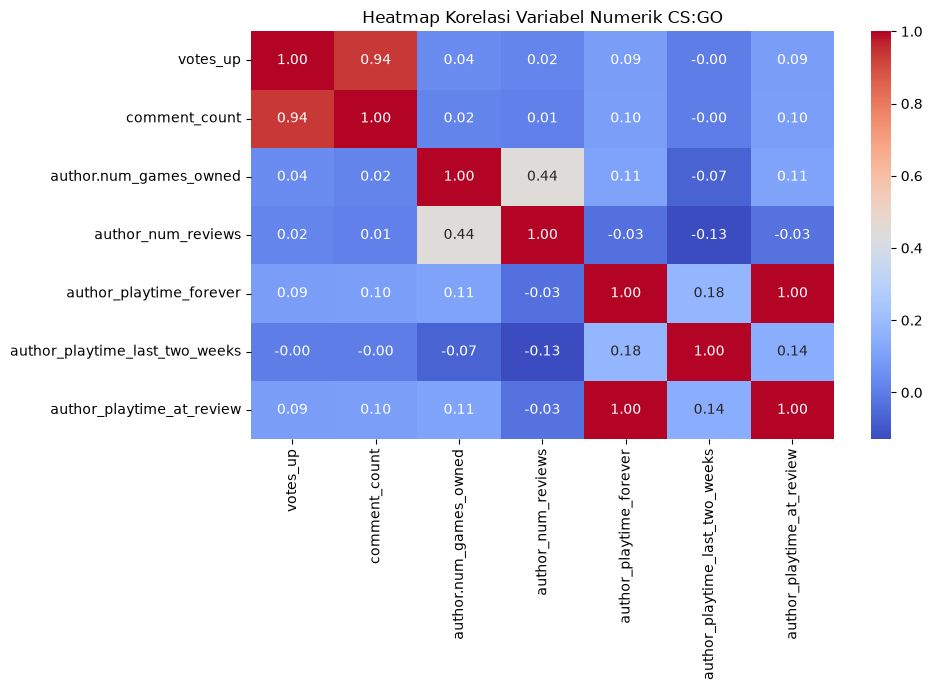

In [18]:
kolom_korelasi = [
    "votes_up",
    "comment_count",
    "author.num_games_owned",
    "author_num_reviews",
    "author_playtime_forever",
    "author_playtime_last_two_weeks",
    "author_playtime_at_review"
]

korelasi = df[kolom_korelasi].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Heatmap Korelasi Variabel Numerik CS:GO")
plt.tight_layout()
plt.show()

Berdasarkan heatmap korelasi, terdapat hubungan positif yang kuat antara `votes_up` dan `comment_count`, dengan nilai korelasi sekitar 0,94. Hal ini menunjukkan bahwa jumlah upvote dan jumlah komentar pada ulasan cenderung meningkat bersama dalam dataset ini.

Selain itu, variabel `author_playtime_forever` dan `author_playtime_at_review` memiliki korelasi yang hampir sempurna, yaitu sekitar 1,00. Kedua variabel tersebut berkaitan erat dengan waktu bermain pemain. Sementara itu, hubungan antara jumlah game yang dimiliki pemain dan jumlah ulasan yang ditulis memiliki korelasi positif sedang, yaitu sekitar 0,44.

Sebagian besar pasangan variabel lainnya menunjukkan korelasi yang relatif lemah. Hasil ini menggambarkan hubungan antarvariabel dalam dataset, tetapi tidak membuktikan hubungan sebab-akibat. Nilai korelasi yang tinggi juga perlu ditafsirkan dengan hati-hati karena distribusi data dan nilai ekstrem dapat memengaruhi hasilnya.

#

### 5. Kesimpulan

Berdasarkan analisis yang telah dilakukan, dataset ulasan pemain CS:GO di Steam terdiri dari 15.640 baris data dan 16 kolom. Hasil pemeriksaan menunjukkan bahwa terdapat 54 data kosong pada kolom `review` dan tidak ditemukan baris duplikat. Data yang kosong tetap dipertahankan pada dataset utama karena masih memiliki informasi lain yang dapat digunakan dalam analisis.

Hasil analisis menunjukkan bahwa sebanyak 13.979 ulasan atau 89,38% termasuk kategori positif, sedangkan 1.661 ulasan atau 10,62% termasuk kategori negatif berdasarkan nilai `voted_up`. Median waktu bermain pemain yang memberikan ulasan negatif adalah sekitar 242,13 jam, lebih tinggi daripada median pemain yang memberikan ulasan positif, yaitu sekitar 122,40 jam. Namun, hasil ini tidak berarti bahwa waktu bermain yang lebih lama menyebabkan pemain memberikan ulasan negatif.

Analisis upvote menunjukkan bahwa 85,98% ulasan belum mendapatkan upvote. Selain itu, seluruh data dalam dataset menggunakan bahasa Inggris. Perbandingan status pembelian menunjukkan bahwa persentase ulasan positif pada kelompok yang membeli game melalui Steam sebesar 88,85%, sedangkan pada kelompok yang tidak tercatat membeli melalui Steam sebesar 90,01%.

Berdasarkan histogram, beberapa variabel numerik memiliki distribusi yang condong ke kanan, dengan sebagian besar nilai berada pada rentang rendah dan sebagian kecil memiliki nilai yang sangat tinggi. Hasil heatmap juga menunjukkan korelasi positif yang kuat antara jumlah upvote dan jumlah komentar, serta korelasi yang hampir sempurna antara dua variabel waktu bermain yang dianalisis.

Secara keseluruhan, EDA ini memberikan gambaran mengenai pola ulasan pemain CS:GO berdasarkan rekomendasi, waktu bermain, upvote, bahasa, status pembelian, dan hubungan antarvariabel numerik. Hasil analisis hanya menggambarkan dataset yang digunakan dan tidak secara langsung membuktikan sebab-akibat ataupun mewakili seluruh pemain CS:GO.